# Visualizaciones creativas con la base Pima en español

Se utilizará la base **Pima Indians Diabetes**, con nombres de las variables en español y genera visualizaciones clásicas y novedosas, incluyendo **Sankey**, **Sunburst**, **Treemap**, **Radar**, **Bubble chart** y **Parallel Coordinates**.

## 1. Librerías


In [1]:

# Si te falta alguna librería, descomentá esta línea:
# !pip install pandas numpy matplotlib seaborn plotly scikit-learn

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go

from IPython.display import display

# Configuración visual general
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


## 2. Carga de la base

La notebook intenta cargar la base desde un archivo local `pima_es.csv`. Si no existe, la debemos descargar desde la URL pública:
https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database/data

https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv
y luego renombra las columnas al español.

In [4]:

# Opción A: si ya tenemos la carpeta en el CCad, el archivo de la base la dejamos allí, en la misma carpeta que esta esta notebook
ruta_local = "pima_es.csv"

# Opción B: si no tenemos la base alli, la descargaremos desde la URL pública
url_pima = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columnas_originales = [
    "pregnancies",
    "glucose",
    "blood_pressure",
    "skin_thickness",
    "insulin",
    "bmi",
    "diabetes_pedigree",
    "age",
    "outcome"
]

columnas_es = {
    "pregnancies": "embarazos",
    "glucose": "glucosa",
    "blood_pressure": "presion_arterial",
    "skin_thickness": "pliegue_cutaneo",
    "insulin": "insulina",
    "bmi": "imc",
    "diabetes_pedigree": "pedigri_diabetes",
    "age": "edad",
    "outcome": "resultado"
}

try:
    df = pd.read_csv(ruta_local)
    print("Base cargada desde archivo local:", ruta_local)
except FileNotFoundError:
    df = pd.read_csv(url_pima, header=None, names=columnas_originales)
    df = df.rename(columns=columnas_es)
    print("Base descargada desde URL pública.")

# Si el archivo local ya tenía nombres en inglés, también renombramos:
df = df.rename(columns=columnas_es)

df.head()


Base descargada desde URL pública.


In [3]:
# Si el archivo local ya tenía nombres en inglés, también renombramos:
df = df.rename(columns=columnas_es)

df.head()

,embarazos,glucosa,presion_arterial,pliegue_cutaneo,insulina,imc,pedigri_diabetes,edad,resultado
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 3. Revisión inicial de la base

In [5]:

print("Dimensiones:", df.shape)
print("\nTipos de datos:")
display(df.dtypes)

print("\nValores nulos por columna:")
display(df.isnull().sum())

print("\nResumen estadístico:")
display(df.describe())


Dimensiones: (768, 9)

Tipos de datos:


,0
embarazos,int64
glucosa,int64
presion_arterial,int64
pliegue_cutaneo,int64
insulina,int64
imc,float64
pedigri_diabetes,float64
edad,int64
resultado,int64



Valores nulos por columna:


,0
embarazos,0
glucosa,0
presion_arterial,0
pliegue_cutaneo,0
insulina,0
imc,0
pedigri_diabetes,0
edad,0
resultado,0



Resumen estadístico:


,embarazos,glucosa,presion_arterial,pliegue_cutaneo,insulina,imc,pedigri_diabetes,edad,resultado
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## 4. Etiquetas más claras para el diagnóstico

In [6]:

df["diagnostico"] = df["resultado"].map({0: "Sin diabetes", 1: "Con diabetes"})
df["resultado_num"] = df["resultado"]  # la dejamos también en versión numérica para algunos gráficos

df[["resultado", "diagnostico"]].head()


,resultado,diagnostico
0,1,Con diabetes
1,0,Sin diabetes
2,1,Con diabetes
3,0,Sin diabetes
4,1,Con diabetes


## 5. Visualizaciones básicas

Primero armamos algunas visualizaciones más tradicionales, útiles para introducir la base.

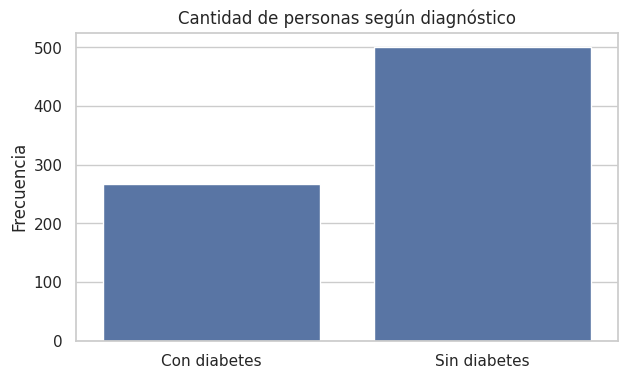

In [7]:

# Distribución del diagnóstico
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x="diagnostico")
ax.set_title("Cantidad de personas según diagnóstico")
ax.set_xlabel("")
ax.set_ylabel("Frecuencia")
plt.show()


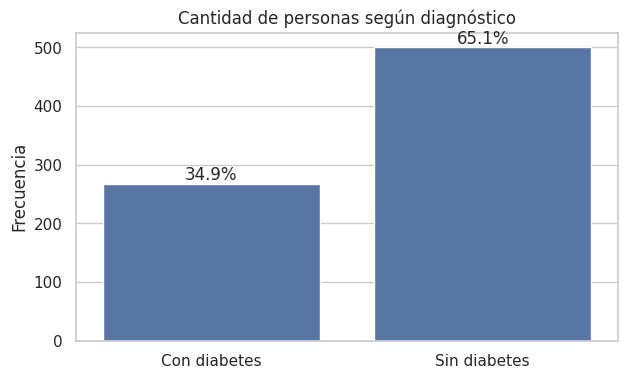

In [8]:

plt.figure(figsize=(7, 4))

ax = sns.countplot(data=df, x="diagnostico")

# Total de observaciones
total = len(df)

# Agregar porcentaje arriba de cada barra
for p in ax.patches:
    height = p.get_height()
    porcentaje = 100 * height / total

    ax.annotate(f'{porcentaje:.1f}%',
                (p.get_x() + p.get_width() / 2, height),
                ha='center', va='bottom')

ax.set_title("Cantidad de personas según diagnóstico")
ax.set_xlabel("")
ax.set_ylabel("Frecuencia")

plt.show()

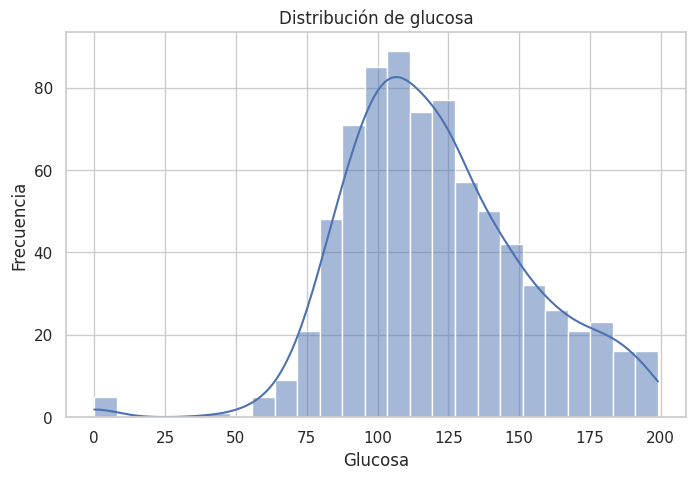

In [9]:

# Histograma de glucosa
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="glucosa", bins=25, kde=True)
plt.title("Distribución de glucosa")
plt.xlabel("Glucosa")
plt.ylabel("Frecuencia")
plt.show()


In [10]:
df[df["glucosa"] == 0]

,embarazos,glucosa,presion_arterial,pliegue_cutaneo,insulina,imc,pedigri_diabetes,edad,resultado,diagnostico,resultado_num
75,1,0,48,20,0,24.7,0.140,22,0,Sin diabetes,0
182,1,0,74,20,23,27.7,0.299,21,0,Sin diabetes,0
342,1,0,68,35,0,32.0,0.389,22,0,Sin diabetes,0
349,5,0,80,32,0,41.0,0.346,37,1,Con diabetes,1
502,6,0,68,41,0,39.0,0.727,41,1,Con diabetes,1


¿Qué hacemos entonces? Imputamos con algo que no perjudique nuestros análisis en este contexto


In [11]:
# con este comando vemos el Indice de la tabla:
df[df["glucosa"] == 0].index

Index([75, 182, 342, 349, 502], dtype='int64')

In [18]:
# contamos cuantos ceros hay
(df["glucosa"] == 0).sum()

np.int64(5)

# Comparamos con el resto de variables para ver si hay otros registros raros (solo de esos 5 registros)
#variables que no pueden ser  ceros:

glucosa
presión arterial
espesor de piel
insulina
BMI (peso relativo)

In [20]:

df[df["glucosa"] == 0].describe()

,embarazos,glucosa,presion_arterial,pliegue_cutaneo,insulina,imc,pedigri_diabetes,edad,resultado,resultado_num
count,5.00000,5.0,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
mean,2.80000,0.0,67.600000,29.600000,4.600000,32.880000,0.380200,28.600000,0.400000,0.400000
std,2.48998,0.0,12.033287,9.343447,10.285913,7.033989,0.215527,9.607289,0.547723,0.547723
min,1.00000,0.0,48.000000,20.000000,0.000000,24.700000,0.140000,21.000000,0.000000,0.000000
25%,1.00000,0.0,68.000000,20.000000,0.000000,27.700000,0.299000,22.000000,0.000000,0.000000
50%,1.00000,0.0,68.000000,32.000000,0.000000,32.000000,0.346000,22.000000,0.000000,0.000000
75%,5.00000,0.0,74.000000,35.000000,0.000000,39.000000,0.389000,37.000000,1.000000,1.000000
max,6.00000,0.0,80.000000,41.000000,23.000000,41.000000,0.727000,41.000000,1.000000,1.000000


In [21]:
df["glucosa"] = df["glucosa"].replace(0, np.nan)


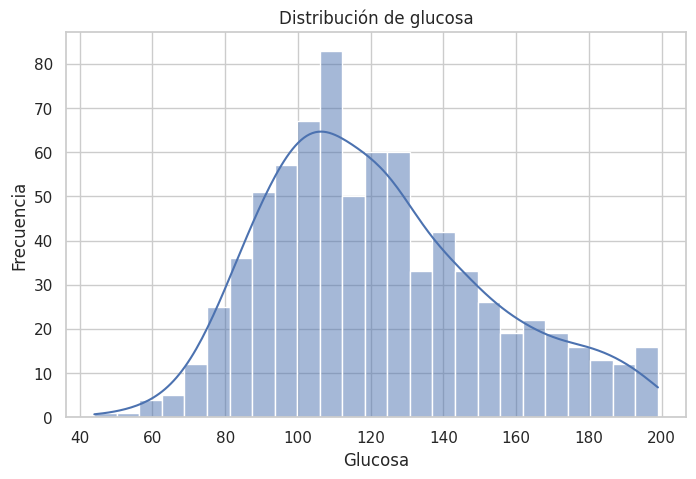

In [22]:
# Histograma de glucosa
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="glucosa", bins=25, kde=True)
plt.title("Distribución de glucosa")
plt.xlabel("Glucosa")
plt.ylabel("Frecuencia")
plt.show()


In [23]:

# Violin plot de IMC por diagnóstico
fig = px.violin(
    df,
    x="diagnostico",
    y="imc",
    color="diagnostico",
    box=True,
    points="all",
    title="Distribución del IMC según diagnóstico"
)
fig.show()


## 6. Crear categorías para visualizaciones novedosas

Para Sankey, Sunburst y Treemap conviene transformar algunas variables numéricas en rangos o categorías.

In [25]:

# Copia para visualizaciones categóricas
df_cat = df.copy()

# Categorías de glucosa
df_cat["glucosa_cat"] = pd.cut(
    df_cat["glucosa"],
    bins=[0, 99, 125, np.inf],
    labels=["Glucosa normal", "Prediabetes", "Glucosa alta"],
    include_lowest=True
)

# Categorías de IMC
df_cat["imc_cat"] = pd.cut(
    df_cat["imc"],
    bins=[0, 18.5, 24.9, 29.9, np.inf],
    labels=["Bajo peso", "Normal", "Sobrepeso", "Obesidad"],
    include_lowest=True
)

# Categorías de edad
df_cat["edad_cat"] = pd.cut(
    df_cat["edad"],
    bins=[20, 30, 40, 50, np.inf],
    labels=["20-30", "31-40", "41-50", "51 o más"],
    include_lowest=True
)

df_cat[["glucosa", "glucosa_cat", "imc", "imc_cat", "edad", "edad_cat", "diagnostico"]].head()


,glucosa,glucosa_cat,imc,imc_cat,edad,edad_cat,diagnostico
0,148.0,Glucosa alta,33.6,Obesidad,50,41-50,Con diabetes
1,85.0,Glucosa normal,26.6,Sobrepeso,31,31-40,Sin diabetes
2,183.0,Glucosa alta,23.3,Normal,32,31-40,Con diabetes
3,89.0,Glucosa normal,28.1,Sobrepeso,21,20-30,Sin diabetes
4,137.0,Glucosa alta,43.1,Obesidad,33,31-40,Con diabetes


## 7. Bubble chart

Este gráfico permite ver varias variables al mismo tiempo:
- eje X: glucosa
- eje Y: IMC
- tamaño: edad
- color: diagnóstico

In [26]:

fig = px.scatter(
    df,
    x="glucosa",
    y="imc",
    size="edad",
    color="diagnostico",
    hover_data=["embarazos", "presion_arterial", "insulina"],
    title="Bubble chart: glucosa, IMC, edad y diagnóstico",
    labels={"glucosa": "Glucosa", "imc": "IMC", "edad": "Edad"}
)
fig.show()


## 8. Heatmap de correlaciones

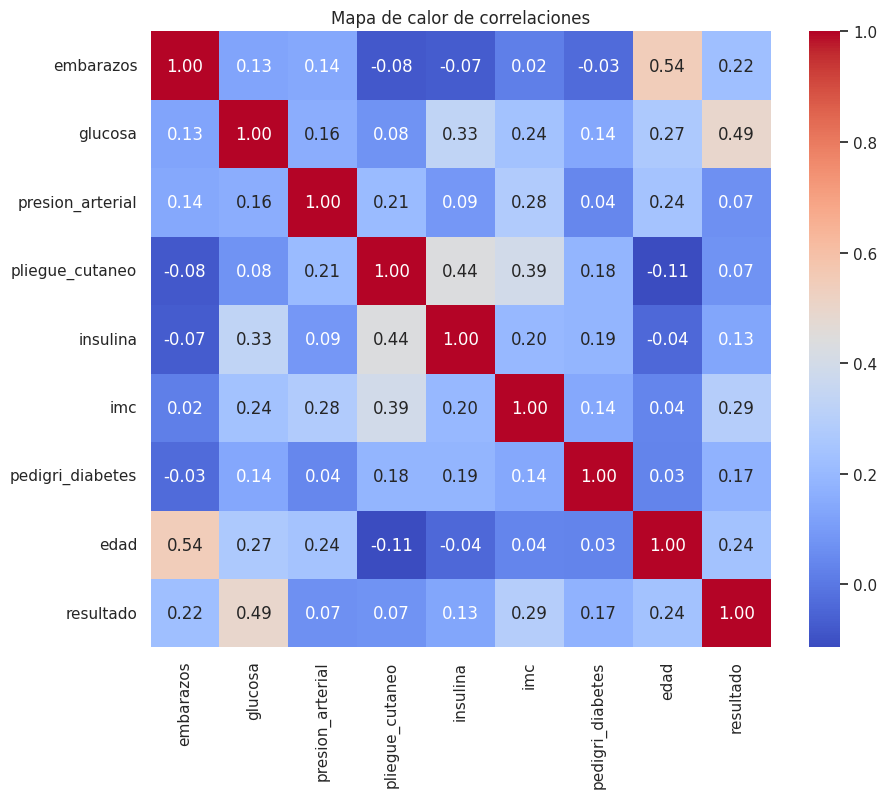

In [27]:

plt.figure(figsize=(10, 8))
corr = df[["embarazos", "glucosa", "presion_arterial", "pliegue_cutaneo",
           "insulina", "imc", "pedigri_diabetes", "edad", "resultado"]].corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Mapa de calor de correlaciones")
plt.show()


## 9. Sunburst

Muestra una jerarquía de categorías: diagnóstico → glucosa → IMC.

In [12]:

fig = px.sunburst(
    df_cat,
    path=["diagnostico", "glucosa_cat", "imc_cat"],
    title="Jerarquía entre diagnóstico, glucosa e IMC"
)
fig.show()


/usr/local/lib/python3.12/dist-packages/plotly/express/_core.py:1727: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/usr/local/lib/python3.12/dist-packages/plotly/express/_core.py:1727: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



## 10. Treemap

Otra forma novedosa de mostrar proporciones por categorías.

In [28]:

fig = px.treemap(
    df_cat,
    path=["edad_cat", "imc_cat", "diagnostico"],
    title="Treemap: edad, IMC y diagnóstico"
)
fig.show()


/usr/local/lib/python3.12/dist-packages/plotly/express/_core.py:1727: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/usr/local/lib/python3.12/dist-packages/plotly/express/_core.py:1727: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/usr/local/lib/python3.12/dist-packages/plotly/express/_core.py:1727: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



## 11. Sankey

Este gráfico representa flujos entre categorías.

En este caso mostramos:
**Glucosa categorizada → IMC categorizado → Diagnóstico**

In [29]:

# Flujo 1: glucosa -> imc
flow1 = (
    df_cat.groupby(["glucosa_cat", "imc_cat"], observed=False)
    .size()
    .reset_index(name="cantidad")
)

# Flujo 2: imc -> diagnostico
flow2 = (
    df_cat.groupby(["imc_cat", "diagnostico"], observed=False)
    .size()
    .reset_index(name="cantidad")
)

# Nodos únicos
labels = list(pd.concat([
    flow1["glucosa_cat"].astype(str),
    flow1["imc_cat"].astype(str),
    flow2["diagnostico"].astype(str)
]).unique())

label_to_index = {label: i for i, label in enumerate(labels)}

# Enlaces
source = [label_to_index[x] for x in flow1["glucosa_cat"].astype(str)]
target = [label_to_index[x] for x in flow1["imc_cat"].astype(str)]
value = flow1["cantidad"].tolist()

source += [label_to_index[x] for x in flow2["imc_cat"].astype(str)]
target += [label_to_index[x] for x in flow2["diagnostico"].astype(str)]
value += flow2["cantidad"].tolist()

fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=20,
        thickness=20,
        line=dict(color="black", width=0.5),
        label=labels
    ),
    link=dict(
        source=source,
        target=target,
        value=value
    )
)])

fig.update_layout(
    title_text="Diagrama de Sankey: flujo entre glucosa, IMC y diagnóstico",
    font_size=12
)

fig.show()


## 12. Parallel Coordinates

Ideal para mostrar patrones multivariados. Cada línea representa una persona.

In [15]:

fig = px.parallel_coordinates(
    df,
    color="resultado_num",
    dimensions=["embarazos", "glucosa", "presion_arterial", "imc", "edad"],
    title="Parallel Coordinates: patrones multivariados en Pima",
    labels={
        "embarazos": "Embarazos",
        "glucosa": "Glucosa",
        "presion_arterial": "Presión arterial",
        "imc": "IMC",
        "edad": "Edad",
        "resultado_num": "Resultado"
    }
)
fig.show()


## 13. Radar chart

Compara el perfil promedio de personas con y sin diabetes.

In [33]:

variables_radar = ["embarazos", "glucosa", "presion_arterial", "imc", "edad"]

prom_sin = df[df["diagnostico"] == "Sin diabetes"][variables_radar].mean()
prom_con = df[df["diagnostico"] == "Con diabetes"][variables_radar].mean()

fig = go.Figure()

fig.add_trace(go.Scatterpolar(
    r=prom_sin.values,
    theta=variables_radar,
    fill="toself",
    name="Sin diabetes"
))

fig.add_trace(go.Scatterpolar(
    r=prom_con.values,
    theta=variables_radar,
    fill="toself",
    name="Con diabetes"
))

fig.update_layout(
    polar=dict(radialaxis=dict(visible=True)),
    title="Perfil promedio por diagnóstico"
)

fig.show()


## 14. Pairplot opcional

Puede tardar un poco más, pero sirve para explorar relaciones bivariadas.

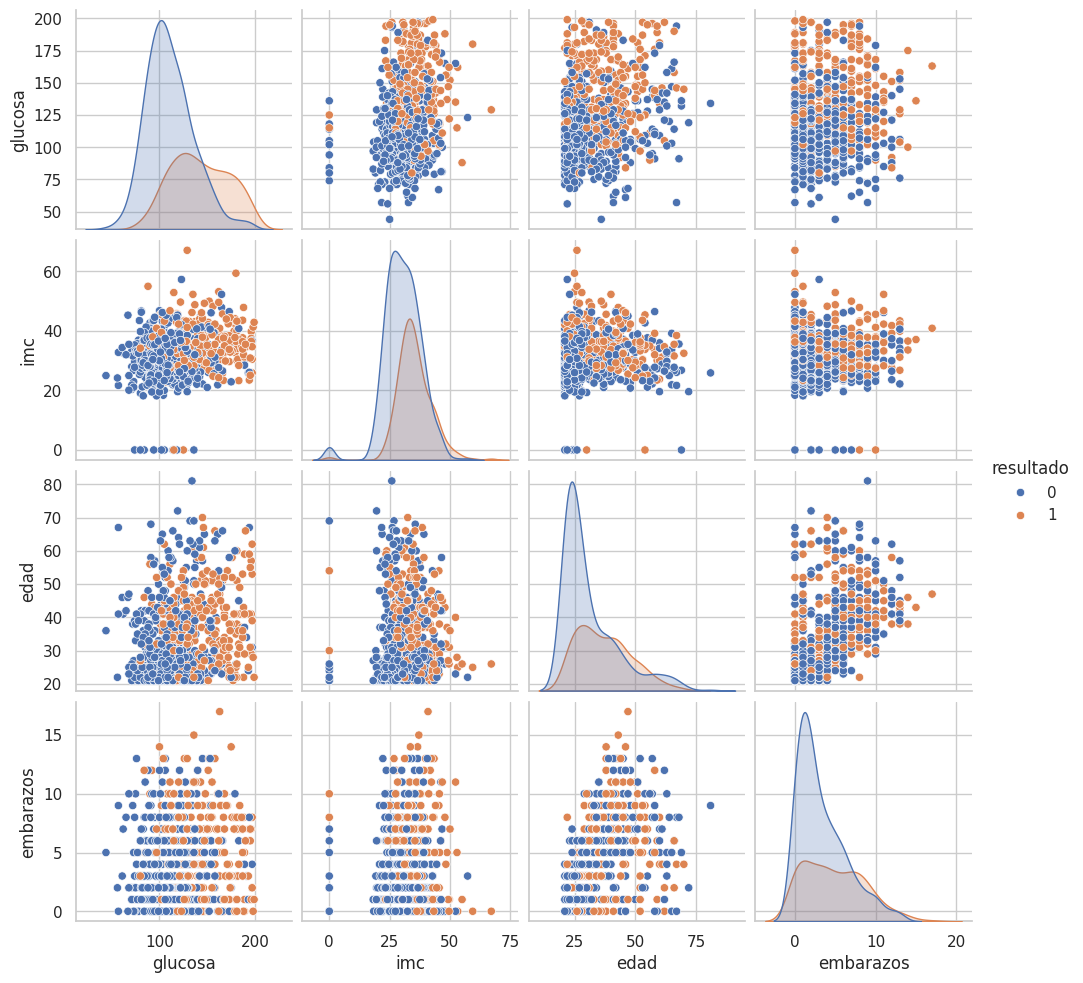

In [34]:

sns.pairplot(
    df[["glucosa", "imc", "edad", "embarazos", "resultado"]],
    hue="resultado"
)
plt.show()


## 15. Algunas conclusiones

- La **glucosa** suele ser una de las variables más asociadas al diagnóstico.
- El **IMC** también muestra diferencias entre personas con y sin diabetes.
- En salud, muchas veces no alcanza con mirar una sola variable: conviene observar **patrones multivariados**.

## 16. Actividad

1. Cambiar los puntos de corte de glucosa e IMC,
2. Armar un Sankey distinto,
3. Interpretar
4. Categorizar otra variable ejemplo: `presion_cat` o `edad_cat`.